In [1]:
%cd ..

/Users/maxschmaltz/Documents/DieKonstraintsPrivat/comp_modeling


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict
from itertools import product
import json
from typing import List, Optional

from data_utils.load_datasets import (
    load_constraints,
    load_appl_ind,
    save_tsv_generic,
    load_tsv_generic
)
from comp_modeling.compxconstraints import CompXConstraints, DEF_ID

Load GermaNet data...: 100%|█████████▉| 99.99999999999996/100 [00:13<00:00,  7.67it/s] 
Load Wiktionary data...: 100%|██████████| 100.0/100 [00:00<00:00, 294.10it/s]            
Load Ili records...: 100%|██████████| 100.0/100 [00:00<00:00, 133321.81it/s]


In [3]:
constr_path = "constraints/constraints_all_revised.yaml"

constraints = load_constraints(constr_path)

In [4]:
# from main.py
s = lambda x: "+" if x else "-"
param_keys = [
    f"{s(count_def)}count_def|{s(coop)}coop|{s(l2p)}l2p"
    for count_def, coop, l2p in product([True, False], repeat=3)
]

## Dataset & Constraint Interaction Complexity

Our modeling dataset consists of ~900 compounds (36 unique N1s) with all implemented constraints defined over them. We derived it by intersecting the items of _GeCoDB\_v07\_GN_ and _SP18\_Pl\_Constr_.

In [5]:
appl_ind_path = "resources/developed/merged_geco_sp_appl_ind.tsv"

appl_ind = load_appl_ind(
    appl_ind_path=appl_ind_path,
    # this dataset is clean
    remove_na_columns=False,
    remove_unconfirmed=False,
    remove_missing=False
)

appl_ind.sample(5)

,linker,def-0_is_applicable,def-0_applies,p2l:decl_cl:pl:#0-0|def-0_is_applicable,p2l:decl_cl:pl:#0-0|def-0_applies,p2l:decl_cl:pl:#s-0_is_applicable,p2l:decl_cl:pl:#s-0_applies,p2l:decl_cl:pl:#e-0|def-0_is_applicable,p2l:decl_cl:pl:#e-0|def-0_applies,p2l:decl_cl:pl:#er-0/er|def-0/er_is_applicable,...,p2l:decl_cl:pl:#e_uml-0|pl_interpr-e_uml_is_applicable,p2l:decl_cl:pl:#e_uml-0|pl_interpr-e_uml_applies,p2l:decl_cl:pl:#0_uml-0|pl_interpr-0_uml_is_applicable,p2l:decl_cl:pl:#0_uml-0|pl_interpr-0_uml_applies,p2l:decl_cl:mixed-0/s/en|pl_interpr-en_is_applicable,p2l:decl_cl:mixed-0/s/en|pl_interpr-en_applies,p2l:drv:sfx:sfx-s|pl_interpr-en_is_applicable,p2l:drv:sfx:sfx-s|pl_interpr-en_applies,p2l:phon_fin:weak_F_cons$-0/s/en|pl_interpr-en_is_applicable,p2l:phon_fin:weak_F_cons$-0/s/en|pl_interpr-en_applies
comp_gecodb,,,,,,,,,,,,,,,,,,,,,
stadt_raum,_,True,True,False,NaN,False,NaN,False,NaN,False,...,False,NaN,False,NaN,False,NaN,False,NaN,False,NaN
person_+en_verzeichnis,_+en_,True,False,False,NaN,False,NaN,False,NaN,False,...,False,NaN,False,NaN,False,NaN,False,NaN,True,True
stadt_grenze,_,True,True,False,NaN,False,NaN,False,NaN,False,...,False,NaN,False,NaN,False,NaN,False,NaN,False,NaN
vogel_bestand,_,True,True,False,NaN,False,NaN,False,NaN,False,...,False,NaN,False,NaN,False,NaN,False,NaN,False,NaN
schloss_brauerei,_,True,True,False,NaN,False,NaN,False,NaN,True,...,False,NaN,False,NaN,False,NaN,False,NaN,False,NaN


Since Schäfer & Pankratz 2018 targeted nouns that exhibit an alternation between a pluralic and a non-pluralic linker, _SP18\_Pl\_Constr_ (hence, our modeling dataset) mostly contains simplex masculine and neutral nouns, which prevail among compounds that satisfy this condition. This leads to a noticeable limitation of the dataset: phonological and especially derivational generative constraints are largely underused in it. Thus, only $50\%$ and $20\%$ of these constraints, respectively, enter the modeling of this dataset.

In [6]:
with open("out/acceptable_linkers.json", encoding="utf-8") as i:
    acceptable_linkers_all = json.load(i)

with open("out/unacceptable_linkers.json", encoding="utf-8") as i:
    unacceptable_linkers_all = json.load(i)

In [7]:
used_constrs = set()
for acceptable_linkers in acceptable_linkers_all.values():
    for linker, constrs in acceptable_linkers.items():
        used_constrs.update(constrs)
for unacceptable_linkers in unacceptable_linkers_all.values():
    for linker, constrs in unacceptable_linkers.items():
        used_constrs.update(constrs)

used_constrs = list(used_constrs)

involved_domains_data = defaultdict(lambda: defaultdict(int))
linkers_by_domains_data = defaultdict(lambda: defaultdict(list))
for c_id in used_constrs:
    if c_id.startswith("p2l:") or c_id == "l2p:en|non_par_m" or c_id == DEF_ID:
        key = ("gen", "ours")
    else:
        key = ("restr", "ours")
    domains = constraints[c_id]["domain_type"]
    for domain in domains:
        involved_domains_data[domain][key] += 1
    if key == ("gen", "ours"):
        domains_str = "+".join(sorted(domains))
        constr_acc_linkers = CompXConstraints.esc_batch(constraints[c_id]["acceptable_linkers"])
        for linker in constr_acc_linkers:
            linkers_by_domains_data[linker][(domains_str, "constraints")].append(c_id)
            

involved_domains_df = pd.DataFrame(involved_domains_data).fillna(0).astype(int)
# involved_domains_df.insert(0, "total", involved_domains_df.sum(axis=1))
involved_domains_df = involved_domains_df.T
involved_domains_df.drop("default", inplace=True)

In [8]:
used_constrs_ref = [
    c_id for c_id, constr in constraints.items()
    if constr["measures"] != "NA" and
    constr["measures"]["regularity"]["item"] >= 0.5
]

involved_domains_ref_data = defaultdict(lambda: defaultdict(int))
for c_id in used_constrs_ref:
    if c_id.startswith("p2l:") or c_id == "l2p:en|non_par_m" or c_id == DEF_ID:
        key = ("gen", "reference")
    else:
        key = ("restr", "reference")
    for domain in constraints[c_id]["domain_type"]:
        involved_domains_ref_data[domain][key] += 1

involved_domains_ref_df = pd.DataFrame(involved_domains_ref_data).fillna(0).astype(int)
involved_domains_ref_df = involved_domains_ref_df.T
involved_domains_ref_df.drop("default", inplace=True)

In [9]:
involved_domains_comparison_df = pd.concat((involved_domains_ref_df, involved_domains_df), axis=1)
for key in ["gen", "restr"]:
    involved_domains_comparison_df[(key, "%")] = (100 * (
        involved_domains_comparison_df[(key, "ours")] /
        involved_domains_comparison_df[(key, "reference")]
    )).fillna(100).astype(int)
involved_domains_comparison_df = involved_domains_comparison_df[
    sorted(involved_domains_comparison_df.columns)
]

save_tsv_generic(involved_domains_comparison_df, "out/involved_domains_comparison.tsv")
involved_domains_comparison_df

gen                restr               
                 % ours reference     % ours reference
morphological   75   15        20   100    8         8
derivational    20    2        10   100    7         7
semantic        81    9        11   100    0         0
phonological    50    4         8    85    6         7
lexical        100    0         0   100    1         1

Given that phonological and derivational constraints are the most productive source of _-s-_, this linker is underrepresented in the dataset.

In [10]:
# from main.py
linkers = appl_ind["linker"].tolist()
n = len(linkers)
unique_linkers = np.unique(linkers)
pd.Series({
    l: linkers.count(l) / n
    for l in unique_linkers
}).sort_values(ascending=False).round(3)

_         0.570
_+en_     0.186
_+=er_    0.160
_+e_      0.048
_+=e_     0.015
_+s_      0.015
_+=_      0.007
dtype: float64

Note that the disproportion becomes striking when we consider the actual involvement of these constraints (cf. analogy of lemma vs. token). The "token usage" of the morphological generative constraints at least doubles all the other domain types combined. Semantic constraints are the second most "token-frequent" domain type. Phonology contributes to linker generation slightly, and derivation negligibly little.

In [11]:
active_gen_domains_data = defaultdict(lambda: defaultdict(int))
for constrs in list(acceptable_linkers_all.values()) + list(unacceptable_linkers_all.values()):
    for c_ids in constrs.values():
        for c_id in c_ids:
            if c_id.startswith("p2l:") or c_id == "l2p:en|non_par_m" or c_id == DEF_ID:
                key = "gen"
            else:
                key = "restr"
            for domain in constraints[c_id]["domain_type"]:
                active_gen_domains_data[domain][key] += 1

active_gen_domains_df = pd.DataFrame(active_gen_domains_data).fillna(0).astype(int)
active_gen_domains_df = active_gen_domains_df.T
active_gen_domains_df.drop("default", inplace=True)

save_tsv_generic(active_gen_domains_df, "out/active_gen_domains.tsv")
active_gen_domains_df

,gen,restr
morphological,1816,4180
semantic,498,0
phonological,264,1707
derivational,20,1756
lexical,0,16


This modeling dataset, then, cannot reflect the actual complexity of German nominal compounding, and cannot be used to build the final German compounding model. However, it will still provide a favorable ground for the first attempts of modeling German compounding. First, the simplified constraint interaction will narrow down the subject of study: by focusing on a single morphology vs. semantics interaction, we will not be overwhelmed by the diversity and the number of constraint conflicts. Second, all N1s in the dataset may attach both a pluralic and a non-pluralic linker, thanks to Schäfer & Pankratz 2018. This alternation will make a more representative test of the model because it requires an accurately calibrated apparatus to balance between the two cases for the same input. Third, the small size of the dataset will allow for more detailed inspection of the results. In sum, despite the cons of the dataset, we will be able to produce first insights about constraint conflict resolution with it, and work out a direction for future research. We therefore believe that our modeling dataset is a great baseline for the initial findings.

## Quantitative Overview of Constraint Conflicts

The absolute majority of the compounds are covered by 2-4 generative constraints, with mean of $2.6$ and mode of $2$.

Not all of these constraints necessarily conflict within one compound. On average, every $\sim 1.5$ constraints potentially applicable to one compound actually generate the same linker. This begs the question whether these constraints cooperate during linker generation and jointly increase the probability of their linker. On the other hand, some constraints may return multiple generations. We will henceforth refer to this case as _multi-linker_ constraints, as opposed to _targeted_ constraints.

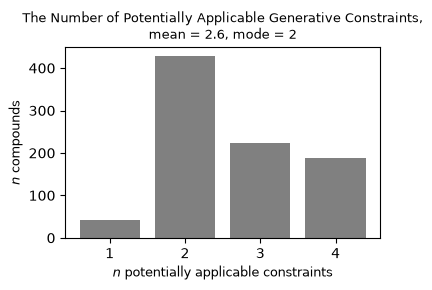

In [12]:
n_constr = [
    len(set([c_id for c_ids in constrs.values() for c_id in c_ids]))
    for constrs in acceptable_linkers_all.values()
]

uc_c = np.unique_counts(n_constr)
x_c = uc_c.values
y_c = uc_c.counts

mean = np.mean(n_constr).round(1)
mode = x_c[y_c.argmax()]

plt.figure(figsize=(4, 3))
plt.bar(x_c, y_c, color="grey")
plt.xlabel(r"$n$ potentially applicable constraints", fontsize=9)
plt.ylabel(r"$n$ compounds", fontsize=9)
plt.title(
    "The Number of Potentially Applicable Generative Constraints,\n"
    f"mean = {mean}, mode = {mode}",
    fontsize=9
)
plt.xticks(x_c)

plt.tight_layout()
plt.savefig("out/n_constrs.png", dpi="figure")
plt.show()

In [13]:
n_accept_linkers = [
    len(accept_linkers)
    for accept_linkers in acceptable_linkers_all.values()
]

(np.array(n_constr) / np.array(n_accept_linkers)).mean().round(1).item()

1.6

In a considerable amount of compounds, the (potentially) cooperating constraints converge to a single generated linker. Still, the constraints generate two linkers for most of the compounds, and even three for some of them (mean, $1.7$, mode $2$).

Remember that these numbers are observed over a modeling dataset with a simplified constraint interaction. The real picture must be more intricate. But again, simplicity is a virtue at this initial attempt to model German compounding: it will be much easier to grasp the first patterns of it from the two-linker outputs.

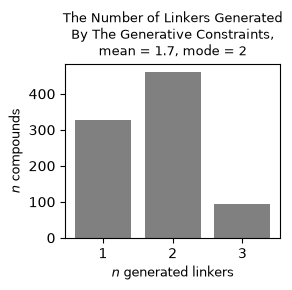

In [14]:
uc_l = np.unique_counts(n_accept_linkers)
x_l = uc_l.values
y_l = uc_l.counts

mean = np.mean(n_accept_linkers).round(1)
mode = x_l[y_l.argmax()]

plt.figure(figsize=(3, 3))
plt.bar(x_l, y_l, color="grey")
plt.xlabel(r"$n$ generated linkers", fontsize=9)
plt.ylabel(r"$n$ compounds", fontsize=9)
plt.title(
    "The Number of Linkers Generated\nBy The Generative Constraints,\n"
    f"mean = {mean}, mode = {mode}",
    fontsize=9
)
plt.xticks(x_l)

plt.tight_layout()
plt.savefig("out/n_generated_linkers.png", dpi="figure")
plt.show()

At the same time, the number of restricted linkers is substantially larger and is 5 or 6 for all the compounds (mean $5.3$, mode $5$).

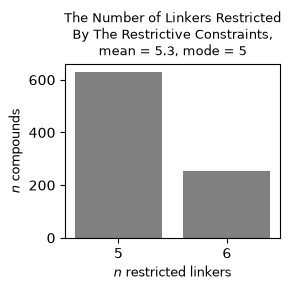

In [15]:
n_unaccept_linkers = [
    len(unaccept_linkers)
    for unaccept_linkers in unacceptable_linkers_all.values()
]

uc_r = np.unique_counts(n_unaccept_linkers)
x_r = uc_r.values
y_r = uc_r.counts

mean = np.mean(n_unaccept_linkers).round(1)
mode = x_r[y_r.argmax()]

plt.figure(figsize=(3, 3))
plt.bar(x_r, y_r, color="grey")
plt.xlabel(r"$n$ restricted linkers", fontsize=9)
plt.ylabel(r"$n$ compounds", fontsize=9)
plt.title(
    "The Number of Linkers Restricted\nBy The Restrictive Constraints,\n"
    f"mean = {mean}, mode = {mode}",
    fontsize=9
)
plt.xticks(x_r)

plt.tight_layout()
plt.savefig("out/n_restricted_linkers.png", dpi="figure")
plt.show()

And still, restrictive linkers may only (potentially!) eliminate a maximum of one linker in a very small number of compounds (mean $0.1$, mode $0$).

The explanation to that lies in the fact that most of the restrictive constraints are paradigm-based and eliminate non-paradigmatic linkers. But since most of the linkers can only be generated paradigmatically in the first place, there is virtually almost no need for these conditions. The restrictive constraints do really come largely into handy when it concerns the _-s-_\linker. Our dataset is just unsuitable to test that because, as discussed, the _-s-_ is underrepresented in our data.

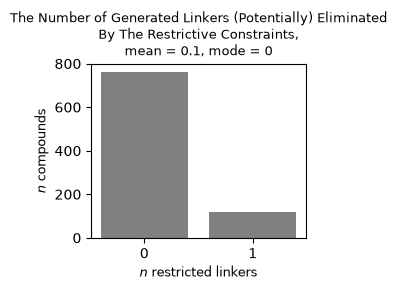

In [16]:
n_eliminated_linkers = [
    len(set(accept_linkers) & set(unaccept_linkers))
    for accept_linkers, unaccept_linkers in zip(
        acceptable_linkers_all.values(), unacceptable_linkers_all.values()
    )
]

uc_e = np.unique_counts(n_eliminated_linkers)
x_e = uc_e.values
y_e = uc_e.counts

mean = np.mean(n_eliminated_linkers).round(1)
mode = x_e[y_e.argmax()]

plt.figure(figsize=(3, 3))
plt.bar(x_e, y_e, color="grey")
plt.xlabel(r"$n$ restricted linkers", fontsize=9)
plt.ylabel(r"$n$ compounds", fontsize=9)
plt.title(
    "The Number of Generated Linkers (Potentially) Eliminated\nBy The Restrictive Constraints,\n"
    f"mean = {mean}, mode = {mode}",
    fontsize=9
)
plt.xticks(x_e)

plt.tight_layout()
plt.savefig("out/n_eliminated_linkers.png", dpi="figure")
plt.show()

## On The Paradox of Semantic Constraints

Pluralic linkers _-e-_, _-"e-_, and _-"0-_ are only ever produced by targeted semantics-involving constraints. Linker _-"er-_ is produced by two targeted semantics-involving constraint and one multi-linker non-semantic constraint. Linker _-en-_ is produced by two targeted semantics-involving constraints, one targeted non-semantic constraints, and two multi-linker non-semantic constraints. In sum, four out of five pluralic linkers are only produced by semantic constraints if we ignore multi-linker constraints. If we include multi-linker constraints back into account, three pluralic linkers are still only produced by semantic constraints. In other words, if we exclude semantics-involving constraints from consideration, we will realistically only be able to produce _-0-_, _-s-_, _-en-_, and maybe _-"er-_.* Indeed, in a dedicated substudy, we predicted the linkers for the entries of the _GeCoDB\_v07\_GN_ dataset, for which the semantic constraints are undefined, using the Albright & Hayes 2002 method. From ~49k trials, only _-0-_, _-s-_, and _-en-_ were ever produced.

This poses a paradox and a modeling challenge for nominal compounding. While the semantic constraints are much less regular, and semantics seems to be only a soft cue in German compounding, it is responsible for at least half of the linker inventory. While the number of the affected compounds is relatively small, it is non-negligible and, and these compounds cannot be conveniently accomodated as exceptions.

In [17]:
linkers_by_domains_df = pd.DataFrame(linkers_by_domains_data)
linkers_by_domains_df.drop(("default", "constraints"), inplace=True)
linkers_by_domains_df = linkers_by_domains_df.T
keys = sorted(linkers_by_domains_df.columns.levels[0], key=lambda x: ("morph" in x), reverse=True)
keys.remove("morphological")
keys.remove("morphological+semantic")
keys = ["morphological", "morphological+semantic"] + keys
keys.remove("default")
col_order = []
for key in keys:
    linkers_by_domains_df[key, "n"] = linkers_by_domains_df[key, "constraints"].map(
        lambda x: len(x) if isinstance(x, list) else 0
    )
    linkers_by_domains_df[key, "constraints"] = linkers_by_domains_df[key, "constraints"].map(
        lambda x: ", ".join(x) if isinstance(x, list) else ""
    )
    col_order.extend([(key, "n"), (key, "constraints")])
linkers_by_domains_df = linkers_by_domains_df[col_order].sort_index()

save_tsv_generic(linkers_by_domains_df, "out/linkers_by_domains.tsv")
linkers_by_domains_df

morphological                                                     \
                   n                                        constraints   
_                  5  p2l:decl_cl:pl:#e_uml-0|def-0, p2l:decl_cl:pl:...   
_+=_               0                                                      
_+=e_              0                                                      
_+=er_             1                   p2l:decl_cl:pl:#er-0/er|def-0/er   
_+e_               0                                                      
_+en_              1                p2l:decl_cl:mixed-0/s/en|def-0/s/en   
_+s_               1                p2l:decl_cl:mixed-0/s/en|def-0/s/en   

       morphological+semantic  \
                            n   
_                           2   
_+=_                        1   
_+=e_                       1   
_+=er_                      2   
_+e_                        1   
_+en_                       1   
_+s_                        0   

                                                           \
                                              constraints   
_       p2l:decl_cl:pl:#er-0/er|mass-interpr-0, p2l:de...   
_+=_             p2l:decl_cl:pl:#0_uml-0|pl_interpr-0_uml   
_+=e_            p2l:decl_cl:pl:#e_uml-0|pl_interpr-e_uml   
_+=er_  p2l:decl_cl:pl:#er-0/er|anim-er, p2l:decl_cl:p...   
_+e_                     p2l:decl_cl:pl:#e-0|pl_interpr-e   
_+en_              p2l:decl_cl:mixed-0/s/en|pl_interpr-en   
_+s_                                                        

       morphological+phonological  \
                                n   
_                               1   
_+=_                            0   
_+=e_                           0   
_+=er_                          0   
_+e_                            0   
_+en_                           1   
_+s_                            1   

                                                     \
                                        constraints   
_       p2l:phon_fin:weak_F_cons$-0/s/en|def-0/s/en   
_+=_                                                  
_+=e_                                                 
_+=er_                                                
_+e_                                                  
_+en_   p2l:phon_fin:weak_F_cons$-0/s/en|def-0/s/en   
_+s_    p2l:phon_fin:weak_F_cons$-0/s/en|def-0/s/en   

       morphological+phonological+semantic  \
                                         n   
_                                        0   
_+=_                                     0   
_+=e_                                    0   
_+=er_                                   0   
_+e_                                     0   
_+en_                                    1   
_+s_                                     0   

                                                       derivational  \
                                           constraints            n   
_                                                                 0   
_+=_                                                              0   
_+=e_                                                             0   
_+=er_                                                            0   
_+e_                                                              0   
_+en_   p2l:phon_fin:weak_F_cons$-0/s/en|pl_interpr-en            0   
_+s_                                                              2   

                                                      phonological  \
                                          constraints            n   
_                                                                1   
_+=_                                                             0   
_+=e_                                                            0   
_+=er_                                                           0   
_+e_                                                             0   
_+en_                                                            1   
_+s_    p2l:drv:sfx:sfx-s|def-s, p2l:d

In [18]:
linkers_by_domains_df[[col for col in linkers_by_domains_df.columns if not "sem" in col[0]]]

morphological                                                     \
                   n                                        constraints   
_                  5  p2l:decl_cl:pl:#e_uml-0|def-0, p2l:decl_cl:pl:...   
_+=_               0                                                      
_+=e_              0                                                      
_+=er_             1                   p2l:decl_cl:pl:#er-0/er|def-0/er   
_+e_               0                                                      
_+en_              1                p2l:decl_cl:mixed-0/s/en|def-0/s/en   
_+s_               1                p2l:decl_cl:mixed-0/s/en|def-0/s/en   

       morphological+phonological  \
                                n   
_                               1   
_+=_                            0   
_+=e_                           0   
_+=er_                          0   
_+e_                            0   
_+en_                           1   
_+s_                            1   

                                                    derivational  \
                                        constraints            n   
_       p2l:phon_fin:weak_F_cons$-0/s/en|def-0/s/en            0   
_+=_                                                           0   
_+=e_                                                          0   
_+=er_                                                         0   
_+e_                                                           0   
_+en_   p2l:phon_fin:weak_F_cons$-0/s/en|def-0/s/en            0   
_+s_    p2l:phon_fin:weak_F_cons$-0/s/en|def-0/s/en            2   

                                                      phonological  \
                                          constraints            n   
_                                                                1   
_+=_                                                             0   
_+=e_                                                            0   
_+=er_                                                           0   
_+e_                                                             0   
_+en_                                                            1   
_+s_    p2l:drv:sfx:sfx-s|def-s, p2l:drv:prx_deverb-s            0   

                                       
                          constraints  
_            p2l:phon_fin:sibilant$-0  
_+=_                                   
_+=e_                                  
_+=er_                                 
_+e_                                   
_+en_   p2l:phon_fin:schwa$-en|def-en  
_+s_

*Note that this would have been the case even if all the constraints were active over the dataset. The missing constraints can only produce _-0-_, _-s-_, and _-en-_, themselves.

In [19]:
unused_constrs = list(set(used_constrs_ref) - set(used_constrs))
unproduced_linkers = set()
for c_id in unused_constrs:
    unproduced_linkers.update(
        CompXConstraints.esc_batch(constraints[c_id]["acceptable_linkers"]
    ))

unproduced_linkers

{'_', '_+en_', '_+s_'}

To demonstrate the generative role of the semantic constraints, we scrutinize the constraint conflicts for each N1 in our dataset.

Out of 36 N1s in our dataset, ten exhibit an alternation of the number of potentially applicable constraints in different compounds.
* N1s 'Mutter', 'Vogel', 'Stadt', 'Weg', 'Zahn' are only covered by the default constraint and a morphological constraint that both predict _-0-_ in the basic case. N1 'Geschenk' belongs to the same case with an additional derivational constraint that generates _-s-_. However, in compounds in which they have a plural reading, a semantic constraint enters the conflict and additionally generates a pluralic linker. For these six N1s, the pluralic linker is _-e-_, _-"e-_, or _-"0-_. As discussed above, involving semantic constraints is the only way to generate these three pluralic linkers. These six N1s are a very representative case thereof. Indeed, for these N1s, only _-0-_ is generated without a semantic constraint, and both _-0-_ and a pluralic linker are generated otherwise.
* N1s 'Bett', 'Person', and 'Schwester' are an example of a semantic constraint being the only targeted constraint for _-en-_ (except for the schwa-constraint which is, obviously, not applicable here).
* The _-"er-_\plural N1s always come with a morphological and a semantic constraint. As opposed to N1s of the other plural types (which only have a constraint for a pluralic reading), the _-"er-_\plural N1s also have one for a singular reading. That is the reason these N1s do not show such an alternation of the number of potentially applicable constraints. Still, the tenth N1 'Ei' is special because it may involve another, non-pluralic semantic constraint, which, however, does not change the generated linkers.

Now keep in mind that further similar N1s may exhibit the same behavior and just don't in our specific dataset. Thus, N1 'Vater' only builds compounds with a singular N1 reading in our dataset, which is why it never interacts with a pluralic constraint. However, there are cases like 'Väterverein' identical to 'Mütterzentrum' where _-"0-_ is generated by the pluralic constraint. Had the compound 'Väterverein' been in the dataset, we would have had the same alternation for N1 'Vater'. This is important insofar that _-e-_, _-"e-_, or _-"0-_ can only be generated by the pluralic semantic constraints, while the restriction of those can only succeed on the unparadigmaticity grounds. Consequently, _-e-_, _-"e-_, and _-"0-_\plural N1s with a singular reading can neither generate, nor restrict these linkers. This is exactly what we see in "semantics-free" cases of 'Vogel', 'Stadt', 'Vater' etc.: their pluralic linkers are undefined. They may have it because it is not restricted (it is paradigmatic) but it is never generated because no necessary pluralic semantic constraint is involved. An unrelated case of undefined linkers is provided by N1s 'Frau' and 'Gerät'. While these cases are of a low relevance at this iteration, it might be reasonable to analyze them in detail in future.

In [20]:
def get_n1s_by_n_constr(n: int) -> List[str]:
    indices = np.where(np.array(n_constr) == n)[0]
    comps = np.array(
        list(acceptable_linkers_all.keys())
    )[indices].tolist()
    n1s = [comp.split("_")[0] for comp in comps]
    unique_n1s = list(set(n1s))
    comp_examples = [comps[n1s.index(n1)] for n1 in unique_n1s]
    return unique_n1s, comp_examples

In [21]:
geco2text = lambda linker: (
    "-" + linker.replace("+", "").replace("=_", "\"0").replace("=", "\"").replace("_", "") + "-"
    if linker.count("_") == 2 else "-0-"
)
unique_linkers = linkers_by_domains_df.index.tolist()
n1_x_constr_data = {}
for i in x_c:
    n1s, examples = get_n1s_by_n_constr(i)
    for n1, example in zip(n1s, examples):
        acceptable_linkers = acceptable_linkers_all[example]
        unacceptable_linkers = unacceptable_linkers_all[example]
        constrs_n1 = set()
        for constrs in acceptable_linkers.values():
            constrs_n1.update(constrs)
        constrs_n1_str = ", ".join(sorted(list(constrs_n1)))
        accept_linkers_str = ", ".join(
            geco2text(linker) for linker in acceptable_linkers.keys()
        )
        unaccept_linkers_str = ", ".join(
            geco2text(linker) for linker in unacceptable_linkers.keys()
        )
        undefined_linkers = ", ".join(
            list(set(unique_linkers) - 
            set(acceptable_linkers.keys()) -
            set(unacceptable_linkers.keys()))
        )
        record = {
            "generated_linkers": accept_linkers_str,
            "restricted_linkers": unaccept_linkers_str,
            "undefined_linkers": undefined_linkers,
            "example": example,
            "constraints": constrs_n1_str
        }
        n1_x_constr_data[(n1, i)] = record

n1_x_constr_df = pd.DataFrame(n1_x_constr_data).T.sort_index()
save_tsv_generic(n1_x_constr_df, "out/n1_x_constr.tsv")
n1_x_constr_df

generated_linkers                  restricted_linkers  \
apfel     2               -0-   -s-, -en-, -e-, -"er-, -"e-, -es-   
bad       3        -0-, -"er-          -s-, -en-, -e-, -"e-, -"0-   
ball      2               -0-         -s-, -en-, -e-, -"er-, -"0-   
bett      2    -0-, -en-, -s-         -s-, -e-, -"er-, -"e-, -"0-   
          3    -0-, -en-, -s-         -s-, -e-, -"er-, -"e-, -"0-   
bild      3        -0-, -"er-          -s-, -en-, -e-, -"e-, -"0-   
brett     4        -0-, -"er-          -s-, -en-, -e-, -"e-, -"0-   
buch      3        -0-, -"er-          -s-, -en-, -e-, -"e-, -"0-   
ei        3        -0-, -"er-          -s-, -en-, -e-, -"e-, -"0-   
          4        -0-, -"er-          -s-, -en-, -e-, -"e-, -"0-   
frau      1               -0-         -s-, -e-, -"er-, -"e-, -"0-   
gerät     2               -0-  -en-, -e-, -"er-, -"e-, -es-, -"0-   
geräusch  4          -0-, -s-  -en-, -e-, -"er-, -"e-, -es-, -"0-   
geschenk  3          -0-, -s-  -en-, -e-, -"er-, -"e-, -es-, -"0-   
          4     -0-, -e-, -s-  -en-, -e-, -"er-, -"e-, -es-, -"0-   
gitarre   2         -0-, -en-   -s-, -e-, -"er-, -"e-, -es-, -"0-   
hand      2               -0-         -s-, -en-, -e-, -"er-, -"0-   
haus      4        -0-, -"er-          -s-, -en-, -e-, -"e-, -"0-   
hemd      2    -0-, -en-, -s-         -s-, -e-, -"er-, -"e-, -"0-   
hund      2               -0-        -s-, -en-, -"er-, -"e-, -"0-   
katze     2         -0-, -en-   -s-, -e-, -"er-, -"e-, -es-, -"0-   
kind      4        -0-, -"er-          -s-, -en-, -e-, -"e-, -"0-   
lied      3        -0-, -"er-          -s-, -en-, -e-, -"e-, -"0-   
mutter    2               -0-   -s-, -en-, -e-, -"er-, -"e-, -es-   
          3         -0-, -"0-   -s-, -en-, -e-, -"er-, -"e-, -es-   
nagel     2               -0-   -s-, -en-, -e-, -"er-, -"e-, -es-   
nation    3    -0-, -s-, -en-        -e-, -"er-, -"e-, -es-, -"0-   
ohr       2    -0-, -en-, -s-         -s-, -e-, -"er-, -"e-, -"0-   
person    2    -0-, -s-, -en-   -s-, -e-, -"er-, -"e-, -es-, -"0-   
          3    -0-, -s-, -en-   -s-, -e-, -"er-, -"e-, -es-, -"0-   
rad       3        -0-, -"er-          -s-, -en-, -e-, -"e-, -"0-   
schloss   4        -0-, -"er-   -s-, -en-, -e-, -"er-, -"e-, -"0-   
schwert   3        -0-, -"er-          -s-, -en-, -e-, -"e-, -"0-   
schwester 2    -0-, -s-, -en-   -s-, -e-, -"er-, -"e-, -es-, -"0-   
          3    -0-, -s-, -en-   -s-, -e-, -"er-, -"e-, -es-, -"0-   
sonne     2         -0-, -en-   -s-, -e-, -"er-, -"e-, -es-, -"0-   
stadt     2               -0-         -s-, -en-, -e-, -"er-, -"0-   
          3         -0-, -"e-         -s-, -en-, -e-, -"er-, -"0-   
vater     2               -0-   -s-, -en-, -e-, -"er-, -"e-, -es-   
vogel     2               -0-   -s-, -en-, -e-, -"er-, -"e-, -es-   
          3         -0-, -"0-   -s-, -en-, -e-, -"er-, -"e-, -es-   
weg       2               -0-        -s-, -en-, -"er-, -"e-, -"0-   
          3          -0-, -e-        -s-, -en-, -"er-, -"e-, -"0-   
wurm      4        -0-, -"er-          -s-, -en-, -e-, -"e-, -"0-   
zahn      2               -0-         -s-, -en-, -e-, -"er-, -"0-   
          3         -0-, -"e-         -s-, -en-, -e-, -"er-, -"0-   

            undefined_linkers                  example  \
apfel     2              _+=_               apfel_baum   
bad       3                       bad_+=er_architektur   
ball      2             _+=e_              ball_besitz   
bett      2                                bett_wäsche   
          3                              bett_+en_zahl   
bild      3                              bild_qualität   
brett     4                             brett_+er_bude   
buch      3                                buch_handel   
ei        3                                    ei_gelb   
          4                                  ei_sprung   
frau      1             _+en_            frau_+en_arzt   
gerät     2              _+s_            gerät_+e_haus   
geräusch  4   

In [22]:
n1_x_constr_df.loc[[
    n1 for n1 in n1_x_constr_df.index.levels[0]
    if len(n1_x_constr_df.loc[n1].index) > 1
]]

generated_linkers                  restricted_linkers  \
bett      2    -0-, -en-, -s-         -s-, -e-, -"er-, -"e-, -"0-   
          3    -0-, -en-, -s-         -s-, -e-, -"er-, -"e-, -"0-   
ei        3        -0-, -"er-          -s-, -en-, -e-, -"e-, -"0-   
          4        -0-, -"er-          -s-, -en-, -e-, -"e-, -"0-   
geschenk  3          -0-, -s-  -en-, -e-, -"er-, -"e-, -es-, -"0-   
          4     -0-, -e-, -s-  -en-, -e-, -"er-, -"e-, -es-, -"0-   
mutter    2               -0-   -s-, -en-, -e-, -"er-, -"e-, -es-   
          3         -0-, -"0-   -s-, -en-, -e-, -"er-, -"e-, -es-   
person    2    -0-, -s-, -en-   -s-, -e-, -"er-, -"e-, -es-, -"0-   
          3    -0-, -s-, -en-   -s-, -e-, -"er-, -"e-, -es-, -"0-   
schwester 2    -0-, -s-, -en-   -s-, -e-, -"er-, -"e-, -es-, -"0-   
          3    -0-, -s-, -en-   -s-, -e-, -"er-, -"e-, -es-, -"0-   
stadt     2               -0-         -s-, -en-, -e-, -"er-, -"0-   
          3         -0-, -"e-         -s-, -en-, -e-, -"er-, -"0-   
vogel     2               -0-   -s-, -en-, -e-, -"er-, -"e-, -es-   
          3         -0-, -"0-   -s-, -en-, -e-, -"er-, -"e-, -es-   
weg       2               -0-        -s-, -en-, -"er-, -"e-, -"0-   
          3          -0-, -e-        -s-, -en-, -"er-, -"e-, -"0-   
zahn      2               -0-         -s-, -en-, -e-, -"er-, -"0-   
          3         -0-, -"e-         -s-, -en-, -e-, -"er-, -"0-   

            undefined_linkers                  example  \
bett      2                                bett_wäsche   
          3                              bett_+en_zahl   
ei        3                                    ei_gelb   
          4                                  ei_sprung   
geschenk  3                              geschenk_idee   
          4                          geschenk_+e_liste   
mutter    2              _+=_           mutter_sprache   
          3                            mutter_+=_treff   
person    2                    person_+en_gesellschaft   
          3                           person_+en_kreis   
schwester 2                           schwester_modell   
          3                          schwester_+n_paar   
stadt     2             _+=e_             stadt_gebiet   
          3                    stadt_+=e_partnerschaft   
vogel     2              _+=_                vogel_art   
          3                                  vogel_zug   
weg       2              _+e_              weg_strecke   
          3                                weg_+e_netz   
zahn      2             _+=e_                zahn_arzt   
          3                               zahn_wechsel   

                                                   constraints  
bett      2         def-0, p2l:decl_cl:mixed-0/s/en|def-0/s/en  
          3  def-0, p2l:decl_cl:mixed-0/s/en|def-0/s/en, p2...  
ei        3  def-0, p2l:decl_cl:pl:#er-0/er|!pl_interpr-0, ...  
          4  def-0, p2l:decl_cl:pl:#er-0/er|!pl_interpr-0, ...  
geschenk  3  def-0, p2l:decl_cl:pl:#e-0|def-0, p2l:drv:prx_...  
          4  def-0, p2l:decl_cl:pl:#e-0|def-0, p2l:decl_cl:...  
mutter    2               def-0, p2l:decl_cl:pl:#0_uml-0|def-0  
          3  def-0, p2l:decl_cl:pl:#0_uml-0|def-0, p2l:decl...  
person    2  def-0, p2l:phon_fin:weak_F_cons$-0/s/en|def-0/...  
          3  def-0, p2l:phon_fin:weak_F_cons$-0/s/en|def-0/...  
schwester 2  def-0, p2l:phon_fin:weak_F_cons$-0/s/en|def-0/...  
          3  def-0, p2l:phon_fin:weak_F_cons$-0/s/en|def-0/...  
stadt     2               def-0, p2l:decl_cl:pl:#e_uml-0|def-0  
          3  def-0, p2l:decl_cl:pl:#e_uml-0|def-0, p2l:decl...  
vogel     2               def-0, p2l:decl_cl:pl:#0_uml-0|def-0  
          3  def-0, p2l:decl_cl:pl:#0_uml-0|def-0, p2l:decl...  
weg       2                   def-0, p2l:decl_cl:pl:#e-0|def-0  
          3  def-0, p2l:decl_cl:pl:#e-0|def-0, p2l:decl_cl:...  
zahn      2               def-0, p2l:decl_cl:pl:#e_uml-0|def-0  
          3  def-0, p2l:decl_cl:pl:#e_uml-0

Finally, the unexpected importance of the semantic constraint is clearly visible on the domain conflict heatmap below. In compounds for which the constraints generate exactly two linkers, the heatmap visualizes the conflicts of domains involved to generate these two linkers. The default constraint is ignored. The $x$ and the $y$ axes mark the domains that generate the first and the second linker, respectively. The domains that generate one linker are gathered as a union of the domains of all the constraints that generate this linker. For example, if in a compound constraint $C1$ (morphological) and a constraint $C2$ (phonological) generate linker $L1$, and a constraint $C3$ (derivational) generates linker $L2$, then the record for this compound on the heatmap will be "morphological+phonological" vs. "derivational". We only concentrate on two-linker generations because the one-linker generations are of no interest, and all of the three-linker generations in our dataset originate from multi-linker constraints (the mixed nouns constraint: 'Bett', the final-consonant feminine noun constraint: 'Person', 'Nation' etc.)*.

As pointed out above, morphology and semantics play the central role in modeling our dataset. This is confirmed by the fact that the absolute majority of the two-linker generations are born in the competition of morphology and an alliance of morphology and semantics** -- exactly the 'Mutter', 'Stadt' etc. cases addressed above. A considerable amount is at the intersection of morphology and an alliance of morphology, semantics, and phonology. These are the cases of sibilant-final _-"er-_\plural N1s with a singular interpretation e.g. 'Schloss', 'Haus' where _-"er-_ is predicted by the multi-linker morphological _-"er-_\plural constraint. When these nouns have a plural reading, it results in morphology + phonology vs. morphology + semantics conflicts (now the semantic constraint also predicts _-"er-_ and not _-0-_). A fascinating case is the morphology + semantics vs. morphology + semantics conflict. It is constituted by _-"er-_\plural N1s with a singular reading that designate animals and persons: 'Kind' and 'Wurm'. While the pluralic semantic constraint strives to assign them a zero linker under the singular reading, another, non-pluralic, semantic constraint predicts _-"er-_ because of their animacy.

In sum, we have an overwhelming presence of morphology and semantics in our dataset. These two domains constitute the most of the domain conflicts in it. The semantic constraints are necessary to generate roughly half the linker inventory. At the same time, the paradox of the semantic constraints makes them really irregular at doing so. Thus, the challenge of the compound modeling over our dataset is to somehow reconcile the necessity of the semantic constraints with their low regularity (and coverage). We now turn to the results of our compound modeling to see how good (or bad) our three models are at doing so.

*While the three-linker generations are excluded from the heatmap, we do not consider them irrelevant. The semantic constraints do not predict a dedicated linker within them, indeed, but can surely increase the probability of it. These cases will also be important during compounding modeling. However, the two-linker predictions both make the majority of the cases and are easier to disentangle. They will therefore serve as a more transparent source of interpreting the modeling outcome.

**Which is, however, only logical, because Schäfer & Pankratz 2018 specifically aimed at creating a dataset for investigating this conflict, even though they did not exactly phrase it as a conflict.

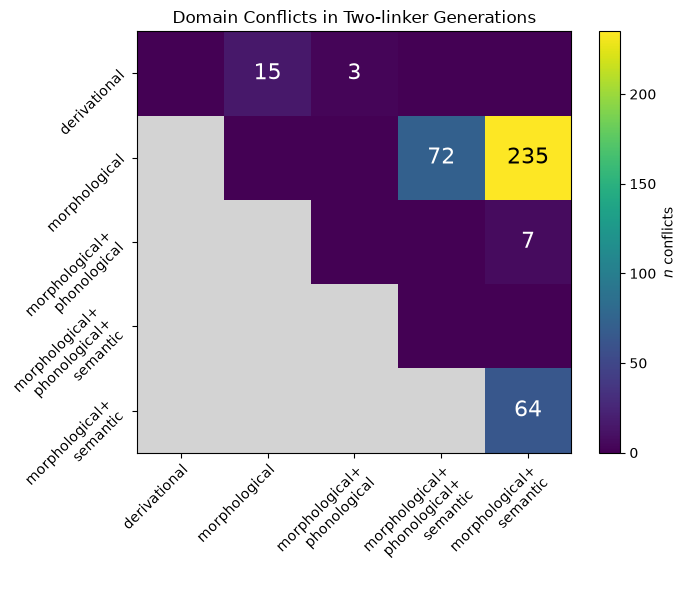

In [23]:
unique_domain_sets = set()
domain_confls_data = defaultdict(lambda: defaultdict(int))
for acceptable_linkers in acceptable_linkers_all.values():
    if len(acceptable_linkers) != 2 or acceptable_linkers.get("_", []) == [DEF_ID]:
        continue
    domains = defaultdict(set)
    keys = list(acceptable_linkers.keys())
    for i in range(len(keys)):
        for c_id in acceptable_linkers[keys[i]]:
            if c_id == DEF_ID:
                continue
            for domain in constraints[c_id]["domain_type"]:
                domains[i].add(domain)
        domains[i] = "+\n".join(sorted(domains[i]))
    domain_confl = sorted(domains.values())
    unique_domain_sets.update(domain_confl)
    domain_confls_data[domain_confl[0]][domain_confl[1]] += 1

domain_map = {
    domain_set: i for i, domain_set in enumerate(sorted(unique_domain_sets))
}
domain_confls_matrix = np.zeros((len(domain_map), len(domain_map)))

for ds1, conflicts in domain_confls_data.items():
    for ds2, n in conflicts.items():
        domain_confls_matrix[domain_map[ds1], domain_map[ds2]] = n

domain_confls_matrix

plt.figure(figsize=(7, 6))
# fade out the lower triangle to indicate symmetricity
# https://stackoverflow.com/a/2332520
lower_mask = np.tri(domain_confls_matrix.shape[0], k=-1)
domain_confls_matrix = np.ma.array(domain_confls_matrix, mask=lower_mask)
# https://matplotlib.org/stable/users/explain/colors/colormaps.html
cmap = plt.cm.viridis.copy()
# https://matplotlib.org/stable/gallery/color/named_colors.html
cmap.set_bad("lightgrey")  # grey where masked
plt.imshow(domain_confls_matrix, cmap=cmap, aspect="auto")
plt.colorbar(label="$n$ conflicts")
plt.title("Domain Conflicts in Two-linker Generations")
ticks, labels = list(domain_map.values()), list(domain_map.keys())
plt.xticks(ticks, labels=labels, fontsize=10, rotation=45, ha="right",rotation_mode="anchor")
plt.yticks(ticks, labels=labels, fontsize=10, rotation=45)

for i, j in product(range(len(domain_map)), repeat=2):
    val = domain_confls_matrix[i, j]
    if val > 0:
        plt.text(
            j, i, f"{int(val)}",
            ha="center", va="center",
            color="white" if val < 200 else "black",
            fontsize=16
        )

plt.tight_layout()
plt.savefig("out/domain_confls.png", dpi="figure")
plt.show()

## Compounding Modeling: Intro

Following Albright & Hayes 2002 and Yang 2016, we adopt the method of iterative rule (interchangeable with generalizations and constraints in this context) application in modeling the linguistic phenomena. They both argue that a linguistic phenomenon may be governed by a set of rules that are defined over different (possibly overlapping) subsets of the relevant vocabulary, rather then a single rule with a bunch of exceptions. The applicability of these rules is defined by the linguistic properties of the input (see potential applicability in Shmalts 2026). They then demonstrate how these rules compete to produce the output. In a nutshell, both Albright & Hayes 2002 and Yang 2016 first sort the available linguistic rules that govern the target phenomenon by some kind of confidence measure. The rules are then iterated over the input in order of decreasing confidence. Each applicable rule generates a candidate, and at the end the candidate generated by the most confident rule wins. The only methodical difference is, Yang 2016 stops generation at the first applicable rule whereas Albright & Hayes 2002 record all the candidates. For the linker ranking experiments we are planning to conduct in the future, the latter method is clearly much more suitable, as it produces a ranking of the candidates.

Where Albright & Hayes 2002 and Yang 2016 diverge significantly in their methods is the confidence score. The confidence score is designed to resolve rule conflicts by preferring the rule with the higher confidence.

Albright & Hayes 2002 suggest that the regularity (reliability in their own terms; TODO: fact check) of the rule plays the definitive role in conflict resolution. They declare what we call type regularity the raw confidence and derive a final confidence from it by adding the absolute coverage into equation. At this iteration, we do not replicate this step and use item regularity instead. TODO: add justification.

In accordance with the Elsewhere Condition (TODO), Yang 2016 proposes that the order of the rule application follows the decrease in rule specificity, starting with the most specific and finishing with the most general (default) rule*. Yang 2016 himself does not providea definition for specificity. We therefore define two variants of "specificity" ourselves:
1. Coverage specificity. Specificity is simply defined by the number of the covered compounds: the more covered compounds, the less specific the constraint.
2. Condition specificity. Specificity of the constraint is defined by the specificity of the linguistic conditions on its potential applicability. This should take into account both the composition of the conditions, and the specificity of each singular condition in its composition. For example, `[PL:e]` is less specific than `[PL:e] & [sem:PL]`, whereas `[coda:VO]` is less specific than `[coda:e]`. 

*While further effects may impact the order of rule application (stem frequency, rule frequency, etc. see Yang 2016), we initially concentrate on specificity alone as the baseline.

We developed the `CompXConstraints` class to implement the iterative rule application and resolve the rule conflicts.

The `method` parameter controls for the employed confidence score: regularity (Albright & Hayes 2002), coverage or condition specificity (Yang 2016).

It is now quite clear if the default constraint actually takes part in the rule competition, or whether it only serves as a backup in case no other rule wins. With parameter `count_def_constr`, we can set whether the default constraint participates in the conflicts.

As discussed above, around $1.5$ constraints generate the same linker within one compound. Parameter `constr_cooperation` determines whether such constraints cooperate and try to jointly win the competition, or whether they are in the conflict with each other, after all.

`restrict_with_l2p` is the most important parameter of it all. It tells the model whether to eliminate the linkers generated by the generative constraints, in case they are restricted from generation by the restrictive constraints. In case `restrict_with_l2p` is set `True`, an additional round of linker elimination follows the generation. During the elimination, the generative and the restrictive constraints compete for the (non)existence of the affected linker. Similar to in-generation conflicts, during the generation-restriction conflicts the linker is eliminated if the confidence of the restrictive constraint is higher than that of the generative constraint. Consequently, if the most confident prediction is eliminated, the second most confident linker is returned as the output. This procedure is a novel advancement relative to the referenced Albright & Hayes 2002 and Yang 2016 methods.

Below, we briefly demonstrate the functionality of the `CompXConstraints` class.

In [100]:
cxc = CompXConstraints(appl_ind.loc["wurm_befall"])

Before the very prediction, generated (acceptable) and restricted (unacceptable) linkers are already known from the constraints.

In [101]:
print("Acceptable linkers:", cxc.acceptable_linkers)
print("Unacceptable linkers:", cxc.unacceptable_linkers)

Acceptable linkers: defaultdict(<class 'list'>, {'_': ['def-0', 'p2l:decl_cl:pl:#er-0/er|def-0/er', 'p2l:decl_cl:pl:#er-0/er|!pl_interpr-0'], '_+=er_': ['p2l:decl_cl:pl:#er-0/er|def-0/er', 'p2l:decl_cl:pl:#er-0/er|anim-er']})
Unacceptable linkers: defaultdict(<class 'list'>, {'_+s_': ['l2p:s|tend_cmpx_morph', 'l2p:s|tend_cmpx_phon', 'l2p:s|tend_!sonority', 'l2p:s|smpx_high_freq'], '_+en_': ['l2p:en|par'], '_+e_': ['l2p:e|par'], '_+=e_': ['l2p:e_uml'], '_+=_': ['l2p:0_uml']})


The prediction procedure itself only resolves their conflict following the specified parameters. During the prediction, the applicable generative constraints are first sorted by confidence as defined by the prediction method. Here `p2l:decl_cl:pl:#er-0/er|!pl_interpr-0` wins because it has the highers regularity*, hence, confidence.

*While `p2l:decl_cl:pl:#er-0/er|def-0/er` is a more regular constraint, it is a multi-linker constraint. In such cases, we distribute the confidence among the linkers.

In [ ]:
cxc.predict(
    method="albright-hayes",
    count_def_constr=True,
    constr_cooperation=False,
    eliminate_with_l2p=False
)
cxc.gen_constr_df

,linker,condition,spec_score,cvg_score,reg,confidence
c_id,,,,,,
p2l:decl_cl:pl:#er-0/er|!pl_interpr-0,_,[PL:er] & [sem:!PL],25.2,0.829,0.622,0.622
def-0,_,NaN,0.0,0.000,0.573,0.573
p2l:decl_cl:pl:#er-0/er|anim-er,_+=er_,[PL:er] & [[sem:anim] | [sem:pers]],28.0,0.997,0.501,0.501
p2l:decl_cl:pl:#er-0/er|def-0/er,_,[PL:er],14.0,0.979,0.815,0.407
p2l:decl_cl:pl:#er-0/er|def-0/er,_+=er_,[PL:er],14.0,0.979,0.815,0.407


If we do count the default constraint out, it does not participate in the competition.

In [103]:
cxc.update_pred_params(count_def_constr=False)
cxc.gen_constr_df

,linker,condition,spec_score,cvg_score,reg,confidence
c_id,,,,,,
p2l:decl_cl:pl:#er-0/er|!pl_interpr-0,_,[PL:er] & [sem:!PL],25.2,0.829,0.622,0.622
p2l:decl_cl:pl:#er-0/er|anim-er,_+=er_,[PL:er] & [[sem:anim] | [sem:pers]],28.0,0.997,0.501,0.501
p2l:decl_cl:pl:#er-0/er|def-0/er,_,[PL:er],14.0,0.979,0.815,0.407
p2l:decl_cl:pl:#er-0/er|def-0/er,_+=er_,[PL:er],14.0,0.979,0.815,0.407


The sorted generative constraints are then aggregated in the final linker scoreboard. For that, the most confident constraint is taken for each of the acceptable linkers.

In [104]:
cxc.linker_scoreboard

,confidence,cvg_score,c_id
linker,,,
_,0.622,0.829,p2l:decl_cl:pl:#er-0/er|!pl_interpr-0
_+=er_,0.501,0.997,p2l:decl_cl:pl:#er-0/er|anim-er


The most confident linker is returned as the prediction.

In [105]:
cxc.y_pred

'_'

Enabling constraint cooperation sums up the confidences of all the constraints for each linker during the linker scoreboard aggregation. Consequently, if there are a few less regular constraints for one linker, they may cooperatively overtake a more regular singular constraint for another linker. In our case, cooperation enabled _-0-_ to win the previously predicted _-en-_ (even with the default linker counted out). The _-0-_\linker, by the way, is the correct linker for this compound.

In [106]:
cxc.update_pred_params(constr_cooperation=True)
cxc.linker_scoreboard

,confidence,cvg_score,c_id
linker,,,
_,1.029,1.808,"p2l:decl_cl:pl:#er-0/er|def-0/er, p2l:decl_cl:..."
_+=er_,0.908,1.976,"p2l:decl_cl:pl:#er-0/er|def-0/er, p2l:decl_cl:..."


Finally, if we enable linker elimination with the restrictive constraints, we will have a list of the restricted constraints sorted the same way as the generative constraints. Currently, the constraints are sorted by the regularity.

In [107]:
cxc = CompXConstraints(appl_ind.loc["geschenk_+e_liste"])
cxc.predict(
    method="albright-hayes",
    count_def_constr=True,
    constr_cooperation=False,
    eliminate_with_l2p=True
)
cxc.restr_constr_df

,linker,condition,spec_score,cvg_score,reg,confidence
c_id,,,,,,
l2p:0_uml,_+=_,[PL:uo],14.0,0.999,1.000,1.000
l2p:e_uml,_+=e_,[PL:ue],14.0,0.997,1.000,1.000
l2p:er|par,_+=er_,[PL:er],14.0,0.991,1.000,1.000
l2p:en|par,_+en_,[PL:en],14.0,0.848,0.985,0.985
l2p:es|mono_syl,_+es_,[nsyl:mono] | [[nsyl:mono] & [drv:PRX]],20.4,0.990,0.972,0.972
l2p:er|smpx,_+=er_,[drv:smpx],14.0,0.991,0.903,0.903
l2p:e|smpx,_+e_,[drv:smpx],14.0,0.991,0.806,0.806


We can see that linker _-e-_ predicted by the generative constraints is actually prohibited by one of the restrictive constraints. If the restrictive constraint is more confident, the linker is eliminated, which is documented in the linker scoreboard.

In [108]:
cxc.linker_scoreboard

,confidence,cvg_score,c_id,removed_by
linker,,,,
_,0.754,0.838,p2l:decl_cl:pl:#e-0|def-0,
_+s_,0.649,0.841,p2l:drv:prx_deverb-s,
_+e_,0.544,0.921,p2l:decl_cl:pl:#e-0|pl_interpr-e,l2p:e|smpx


Right now, the elimination did not affect the output. However, if the most confident linker is eliminated, the next one takes its place, as will be demonstrated with a coverage-based model below.

In [109]:
cxc.update_pred_params(constr_cooperation=False)
cxc.linker_scoreboard

,confidence,cvg_score,c_id,removed_by
linker,,,,
_,0.754,0.838,p2l:decl_cl:pl:#e-0|def-0,
_+s_,0.649,0.841,p2l:drv:prx_deverb-s,
_+e_,0.544,0.921,p2l:decl_cl:pl:#e-0|pl_interpr-e,l2p:e|smpx


And this is how the compounding is modeled with the iterative rule application approach. Changing the method just changes the rule ordering. The coverage specificity method will order the constraints by the increasing coverage. The condition specificity method will order the constraints by the decreasing condition specificity. Operationally, everything stays the same.

In [110]:
cxc.update_pred_params(method="yang-cvg")
cxc.gen_constr_df

,linker,condition,spec_score,cvg_score,reg,confidence
c_id,,,,,,
p2l:decl_cl:pl:#e-0|pl_interpr-e,_+e_,[PL:e] & [sem:PL],26.8,0.921,0.544,0.921
p2l:drv:prx_deverb-s,_+s_,[drv:PRX],12.7,0.841,0.649,0.841
p2l:decl_cl:pl:#e-0|def-0,_,[PL:e],14.0,0.838,0.754,0.838
def-0,_,NaN,0.0,0.000,0.573,0.000


In [111]:
cxc.linker_scoreboard

,confidence,reg,c_id,removed_by
linker,,,,
_+e_,0.921,0.544,p2l:decl_cl:pl:#e-0|pl_interpr-e,l2p:e|smpx
_+s_,0.841,0.649,p2l:drv:prx_deverb-s,
_,0.838,0.754,p2l:decl_cl:pl:#e-0|def-0,


As explained earlier, the most confident linker is removed by a generative constraint, and the second most confident linker is returned instead.

In [112]:
cxc.y_pred

'_+s_'

In [113]:
cxc.update_pred_params(method="yang-cond")
cxc.gen_constr_df

,linker,condition,spec_score,cvg_score,reg,confidence
c_id,,,,,,
p2l:decl_cl:pl:#e-0|pl_interpr-e,_+e_,[PL:e] & [sem:PL],26.8,0.921,0.544,26.8
p2l:decl_cl:pl:#e-0|def-0,_,[PL:e],14.0,0.838,0.754,14.0
p2l:drv:prx_deverb-s,_+s_,[drv:PRX],12.7,0.841,0.649,12.7
def-0,_,NaN,0.0,0.000,0.573,0.0


In [114]:
cxc.linker_scoreboard

,confidence,reg,c_id,removed_by
linker,,,,
_+e_,26.8,0.544,p2l:decl_cl:pl:#e-0|pl_interpr-e,
_,14.0,0.754,p2l:decl_cl:pl:#e-0|def-0,
_+s_,12.7,0.649,p2l:drv:prx_deverb-s,


In [115]:
cxc.y_pred

'_+e_'

## Compounding Modeling: Results

We now turn to the actual results of compound modeling we obtained using the three conflict resolution methods outlined above. For each of the method, we collected and evaluated results with all possible combinations of the conflict resolution parameters discussed (the presence of the default constraints in the conflicts, constraint cooperation, linker elimination).

Below are the metrics of the three methods at their best parameters, and two baseline for comparison: a zero linker and a random baseline.

The good news is, all the three methods are considerably more accurate and linker-diverse than the baselines. This tells us that both regularity, coverage, and condition specificity have at least some predictive power.

The Albright & Hayes 2002 method is not very successful at modeling compounding. With an F1-score of only $0.23$, it is actually closer performance-wise to the random baseline than to the specificity-based methods. The latter, in their turn, are not very far away from each other: the coverage specificity method achieves an F1-score of $0.38$, condition specificity -- $0.4$. These are quite high, considering the awfully imbalanced linker distribution in the dataset. Even despite the simplified constraint interaction in our dataset, we suppose that this is the great achievement for a mere initial attempt that only considers one single parameter to generate the linker.

One can be said right away: the specificity of the constraint -- both conditional and applicational -- is a much stronger predictor than its regularity (alone). Below, we examine the outputs for each method carefully.

In [116]:
load_tsv_generic("out/metrics_summary.tsv")

,acc,f1
yang-cond,0.713,0.403
yang-cvg,0.698,0.375
albright-hayes,0.667,0.230
rand,0.375,0.128
zero,0.570,0.104


### Albright & Hayes 2002

The results are all the same for any model configuration.

We formulate the following questions with this regard:
1. What is the overall composition of the (best*) predictions?
2. How does the method's strategy of conflict resolution explain it?
3. Why are the same results produced regardless of the model configuration?

*The best configuration is marked in the metrics table with the `is_best_key` value.

In [141]:
method_dir = os.path.join("out/albright-hayes")

In [142]:
load_tsv_generic(os.path.join(method_dir, "metrics_summary.tsv"))

,acc,f1,is_best_key
+count_def|+coop|+l2p,0.667,0.23,True
+count_def|+coop|-l2p,0.667,0.23,False
+count_def|-coop|+l2p,0.667,0.23,False
+count_def|-coop|-l2p,0.667,0.23,False
-count_def|+coop|+l2p,0.667,0.23,False
-count_def|+coop|-l2p,0.667,0.23,False
-count_def|-coop|+l2p,0.667,0.23,False
-count_def|-coop|-l2p,0.667,0.23,False


#### The Overall Composition of The (Best) Predictions

In [143]:
ldistr_comparison = load_tsv_generic(os.path.join(method_dir, "ldistr_comparison.tsv"))
f1_acc_df = load_tsv_generic(os.path.join(method_dir, "f1_acc_df.tsv"))
cnf_matrix = load_tsv_generic(os.path.join(method_dir, "confusion_matrix.tsv"))

The Albright & Hayes 2002 method (AH02) overproduces* _-0-_ and underproduces* _-en-_ approximately by half. Linkers _-"er-_ and _-s-_ are largely overproduced. All the other linkers are never produced.

*Relative to the true distribution of the linkers in the dataset.

In [144]:
ldistr_comparison.sort_values(by="ours", ascending=False)

,reference,ours
_,0.570,0.882
_+en_,0.186,0.090
_+=er_,0.160,0.027
_+s_,0.015,0.001
_+e_,0.048,0.000
_+=e_,0.015,0.000
_+=_,0.007,0.000


This consequently leads to a zero accuracy and F1 score over the four non-produced linkers, and a low recall (hence, F1 score) over _-"er-_ and _-s-_. Linker _-en-_, while underproduced, is still handled relatively well by the model, achieving an F1 score of $0.64$. While having a great recall for a zero linker, AH02 is not very precise over it.

Overall, the low F1 score is explained by underproduction (down to the absence) of most explicit linkers, on one hand, and by consequent overfavoring _-0-_, on the other.

In [145]:
f1_acc_df

,acc,f1,N,prec,recall
avg,0.667,0.230,882.0,0.327,0.224
_,0.982,0.771,503.0,0.635,0.982
_+en_,0.476,0.642,164.0,0.987,0.476
_+=er_,0.113,0.194,141.0,0.667,0.113
_+e_,0.000,0.000,42.0,0.000,0.000
_+=e_,0.000,0.000,13.0,0.000,0.000
_+s_,0.000,0.000,13.0,0.000,0.000
_+=_,0.000,0.000,6.0,0.000,0.000


The overproduction of zero originates from the four non-produced linkers: they are all false predicted as zero. The underproduced linkers _-en-_ and _-"er-_ further contribute to overproduction; all but a few false predictions of the _-en-_\linked compounds (about a half) and all of the false predictions of the _-"er-_\linked compounds (almost $90\%$) were predicted a zero linker. The explicit linkers, themselves, were false predicted instead of another linker just a few times.

In [146]:
cnf_matrix

,_,_+en_,_+=er_,_+e_,_+=e_,_+s_,_+=_
_,0.982,0.002,0.016,0.0,0.0,0.000,0.0
_+en_,0.518,0.476,0.000,0.0,0.0,0.006,0.0
_+=er_,0.887,0.000,0.113,0.0,0.0,0.000,0.0
_+e_,1.000,0.000,0.000,0.0,0.0,0.000,0.0
_+=e_,1.000,0.000,0.000,0.0,0.0,0.000,0.0
_+s_,1.000,0.000,0.000,0.0,0.0,0.000,0.0
_+=_,1.000,0.000,0.000,0.0,0.0,0.000,0.0


For such a distribution of the predicted linkers to be the case, the constraint(s) for the zero linker must always win the ones for _-"0-_, _-s-_, _-"e-_, and _-e-_. They should also defeat the ones for _-en-_ and _-"er-_ in most cases. Let's investigate the corresponding constraint conflicts and their resolution under AH02 to understand why this happens.

In [147]:
def get_unique_gen_dfs(
    gen_dfs: dict,
    sample: pd.DataFrame,
    remove_cols: Optional[list]=[]
) -> list:
    unique_gen_dfs = {}
    for comp in sample.index:
        is_new = not any([
            gen_dfs[comp].equals(gen_dfs[member])
            for member in unique_gen_dfs
        ])
        if is_new:
            gen_df = gen_dfs[comp].copy()
            gen_df.drop(columns=remove_cols, inplace=True)
            unique_gen_dfs[comp] = gen_df
    unique_gen_dfs = sorted(unique_gen_dfs.items())
    return unique_gen_dfs

In [ ]:
preds_ah02 = load_tsv_generic(os.path.join(method_dir, "preds.tsv"))

with open(os.path.join(method_dir, "linker_scoreboards.json"), encoding="utf-8") as i:
    scoreboards_ah02 = {
        k: pd.DataFrame.from_dict(v, orient="tight")
        for k, v in json.load(i).items()
    }

with open(os.path.join(method_dir, "gen_constr_dfs.json"), encoding="utf-8") as i:
    gen_dfs_ah02 = {
        k: pd.DataFrame.from_dict(v, orient="tight")
        for k, v in json.load(i).items()
    }

### Closer Examination of Conflict Resolution

Below we can see all unique constraint conflicts.

##### _-e-_, _-"e-_, _-"0-_

We can clearly see right away why the three "semantics-only" linkers discussed above (_-e-_, _-"e-_, _-"0-_) are never produced. These linkers are always paradigmatic, which means the N1s that may attach them have a congruent plural marker. Apart from the optional (!) pluralic constraint that generates these linkers if such N1s have a plural reading, a morphological constraint is always applicable to them which generates _-0-_ on the base of their plural form (e.g. "_-e-_\plural N1s mostly attach _-0-_."). While the pluralic constraints, themselves, are more regular than the default constraint, the ever present morphological constraints for these N1s are all more regular than their pluralic constraints. Thus, in a model based on regularity, these morphological constraints are preferred, and _-0-_ is always produced. Since the pluralic constraints are the only ones that may produce these linkers, there are no further constraints that would back them up to cooperatively overtake _-0-_.

Further constraints cannot win the competition with the morphological constraints, either. The prefixed deverbal constraint (_-s-_, e.g. N1 'Geschenk') is slightly less regular. The participation of the default constraint does not generally change a thing, either because only _-0-_ is ever generated, anyways. The latter fact explains zero influence of linker elimination: there are none constraints to eliminate _-0-_.

Thus, in a regularity-based model, the "semantics-only" linkers _-e-_, _-"e-_, _-"0-_ may never be produced. This is confirmed by the fact that the F1-score for these linkers in $0.0$ in all configurations*.


##### _-s-_

Linker _-s-_ bears a special, marginal character in our dataset. As discussed, our dataset mostly has simplex nouns, while _-s-_ predominantly occurs in complex nouns. Also derivational and phonological constraints which are the primary source of this linker, are largely underused in our data. That leads to that the _-s-_\linked compounds in our dataset are not even nearly representative of its usual occurrence context. Specifically, we have a few mixed nouns ('Hemd') and a few simplex masculine and neuter nouns that occasionally attach _-s-_ ('Hund', 'Kind'), which is, however, rather an exception. Consequently, _-s-_ cannot be produced for these nouns: the mixed nouns constraint is a three-linker constraint, so _-s-_ gets a tiny confidence, which is less than that of the default constraint, and the latter case ('Hund', 'Kind') does not have a further _-s-_\generating constraint defined over it (as said, this is more of an exception!). 

The final picture is the same as with the "semantics-only" constraints. Neither linker elimination nor constraint cooperation nor the default constraint participation change the outcome: _-0-_ is always produced. The F1-score for this linker in $0.0$ in all configurations, too*.

<small>
Note that -s- is not representative over our dataset, at all. In the contexts where it has to appear, indeed, it is generated correctly. For example, after N1 'Nation' it is generated in all the configurations. This generation is incorrect, still, because in our dataset, it only appears in rather rare compounds such as 'Nationenwertung'. In other words, our dataset does not provide an adequate ground for -s- to be generated. The results over this linker are therefore to be ignored.
</small>


##### _-en-_

A more optimistic picture is observed with the _-en-_\linker. Except for rare cases, _-en-_ appears paradigmatically in German. It can therefore appear either with a feminine noun or with a noun of the mixed declination. Considering feminine nouns, it appears often after schwa-final N1s; after consonant-final N1s, its appearance is mostly associated with a plural reading, while its presence in case of a singular reading is not necessary. Mixed nouns are very similar to consonant-final feminine nouns. AH02 grasps all these patterns nicely. For schwa-final consonants, there are only the _-en-_ constraint and the default constraint applicable; the former, being more regular, wins, and this holds for all the configurations. In consonant-final feminine nouns with plural reading and mixed nouns with plural reading, a morphological multi-linker constraint conflicts with a pluralic _-en-_ constraint. The latter is regular for both classes and so it always wins the conflict. Even with constraint cooperation enabled, other linkers cannot compete with _-en-_. The morphological multi-linker constraint produces _-0-_, _-s-_, and _-en-_ for both classes, so enabling constraint cooperation necessarily supports the winning _-en-_, too, and does not let it give up its position. Thus, _-en-_ is always (correctly) produced for these three classes.

What concerns the remaining two classes (consonant-final feminine and mixed nouns with no plural interpretation), _-en-_ can only be produced there with the morphological constraint. Since this constraint produces three linkers, the distributed confidence makes them incapable of competing. Only _-0-_ is produced in these cases (and _-s-_ just a few times, see N1 'Nation').

Similarly to the linkers above, none of the configurations differ in their results**. The three aforementioned classes are always predicted an _-en-_. Cooperation, as well as the default linker participation, cannot relegate _-en-_ in favor of another linker; being a paradigmatic linker, it cannot be eliminated, either. In the latter two classes, the default participation linker can only bring harm to the chances of _-en-_, and constraint cooperation cannot save it because there is no other _-en-_\producing constraint to cooperate with. Since only _-0-_ is produced, and it cannot be eliminated, linker elimination does not increase chances of _-en-_ among such N1s.


##### _-"er-_

The distribution of the predictions for the _-"er-_\linker compounds is similar to what we saw over _-en-_. Only two linkers _-0-_ and _-"er-_ are ever generated for these nouns. On the morphological level, a two-linker constraint generates both _-0-_ and _-"er-_, and consequently distributes the confidence among them. These constraints alone cannot determine the outcome. As apposed to the other pluralic linkers, there are two pluralic constraints defined over _-"er-_\plural N1s. They assign _-"er-_ in case of a plural reading of N1, _-0-_ otherwise. It is clear that these constraints are complementary, they cannot appear together and conflict. There is also a mass meaning constraint that also predicts _-0-_ and is also complementary to those two. The confidence of the morphological constraint is distributed, and none of the two linkers predicted by it can win an ever present pluralic/mass constraint without cooperation. The default constraint is less regular than these constraints, too. Even when the cooperation is on, the same thing happens as with _-en-_: by supporting one linker in cooperation, the morphological constraint inevitably supports the other by the same distributed confidence score, and so cooperation creates zero relative difference. Another constraint that predicts _-"er-_ for animate nouns is too irregular, too, to make a difference. When cooperating with plural meaning, it either contributes to _-"er-_ that would have won, anyways, for the reasons expounded above, or cannot even cooperatively beat the more regular singular reading constraint otherwise. The same happens with the default constraint: it either supports the already winning _-0-_, or cannot overtake the pluralic constraint, also not cooperatively. In other words, whichever constraint is the most regular alone, stays decisive regardless of the cooperation. Thus, the predicted linker is fully determined by the pluralic/mass meaning of N1. Indeed, _-0-_ is always generated when the N1 has a mass or a singular meaning, and _-"er-_ is generated otherwise. The only exception is when the N1 ends with a sibilant. In this case, a more regular sibilant-ending constraint generates _-0-_. In this case, the pluralic/mass constraint suffer the destiny of the constraints defeated by them otherwise. The mass or the singular meaning constraint only contributes to _-0-_, and the pluralic constraint cannot beat _-0-_ (guess what!) even cooperatively. Needless to say, linker elimination cannot affect the result since neither _-"er-_ (it is paradigmatic) either _-0-_ can be removed. F1 scores confirm that the generations for the _-"er-_\linked compounds are immune to configuration changes**.


##### _-0-_

We can see from the summary, that _-0-_\linked compounds belong to all the same classes that were covered above. This is no wonder, since Schäfer & Pankratz 2018 purposefully selected N1s that can attach both pluralic and non-pluralic linkers. Thus, the predictions in these compounds are connected inalienably with the predictions of their counterparts with a pluralic linker. Since the model configuration does not change the outcome for the explicit linkers, it does not do so for _-0-_, either**.

In [ ]:
production_summary = open(
    os.path.join(method_dir, "production_summary.txt"),
    "w", encoding="utf-8"
)
linkers_order = ["_+e_", "_+=e_", "_+=_", "_+s_", "_+en_", "_+=er_", "_"]
for linker in linkers_order:
    sample = preds_ah02[preds_ah02["true"] == linker]
    unique_gen_dfs = get_unique_gen_dfs(
        gen_dfs_ah02,
        sample,
        # irrelevant for AH02
        remove_cols=["condition", "spec_score", "cvg_score"]
    )
    production_summary.write(f"==== LINKER {linker} ====\n\n")
    for example, unique_gen_df in unique_gen_dfs:
        pred = preds_ah02.loc[example, "pred"]
        production_summary.write(f"{example}:\t{pred}\n")
        production_summary.write(f"{unique_gen_df}\n\n\n")

production_summary.close()
with open(
    os.path.join(method_dir, "production_summary.txt"),
    "r", encoding="utf-8"
) as production_summary:
    print(*production_summary.readlines())

==== LINKER _+e_ ====
 
 geräusch_+e_macher:	_
                           linker    reg  confidence
 c_id                                               
 p2l:phon_fin:sibilant$-0       _  0.970       0.970
 p2l:decl_cl:pl:#e-0|def-0      _  0.754       0.754
 p2l:drv:prx_deverb-s        _+s_  0.649       0.649
 def-0                          _  0.573       0.573
 
 
 geschenk_+e_liste:	_
                                  linker    reg  confidence
 c_id                                                      
 p2l:decl_cl:pl:#e-0|def-0             _  0.754       0.754
 p2l:drv:prx_deverb-s               _+s_  0.649       0.649
 def-0                                 _  0.573       0.573
 p2l:decl_cl:pl:#e-0|pl_interpr-e   _+e_  0.544       0.544
 
 
 geschenk_+e_sack:	_
                           linker    reg  confidence
 c_id                                               
 p2l:decl_cl:pl:#e-0|def-0      _  0.754       0.754
 p2l:drv:prx_deverb-s        _+s_  0.649       0.649
 def-0      

*The F1-score for the "semantics-only" linkers _-e-_, _-"e-_, _-"0-_, and for linker _-s-_ is $0.0$ in all configurations.

**The generations of _-en-_, _-"er-_, and _-0-_ are robust with respect to configuration.

In [150]:
pd.DataFrame({
    key: load_tsv_generic(
        os.path.join(method_dir, key, "f1_acc_df.tsv")
    ).loc[linkers_order, "f1"]
    for key in param_keys
}).T

,_+e_,_+=e_,_+=_,_+s_,_+en_,_+=er_,_
+count_def|+coop|+l2p,0.0,0.0,0.0,0.0,0.642,0.194,0.771
+count_def|+coop|-l2p,0.0,0.0,0.0,0.0,0.642,0.194,0.771
+count_def|-coop|+l2p,0.0,0.0,0.0,0.0,0.642,0.194,0.771
+count_def|-coop|-l2p,0.0,0.0,0.0,0.0,0.642,0.194,0.771
-count_def|+coop|+l2p,0.0,0.0,0.0,0.0,0.642,0.194,0.771
-count_def|+coop|-l2p,0.0,0.0,0.0,0.0,0.642,0.194,0.771
-count_def|-coop|+l2p,0.0,0.0,0.0,0.0,0.642,0.194,0.771
-count_def|-coop|-l2p,0.0,0.0,0.0,0.0,0.642,0.194,0.771


### Summary

After scrutinizing for each linker how the AH02 model handles the constraint conflicts in which they are (not) produced, we can now fully explain the model's generations.

1. What is the overall composition of the (best*) predictions?
2. How does the method's strategy of conflict resolution explain it?

The overall composition of the constraint conflicts provides a very unfertile ground for the regularity-based AH02. For the absolute majority (if not all) of the N1s in our dataset, there is some morphological _-0-_\generating constraint that is more regular than the others. Semantic constraints, which are the primary source of the explicit linkers (apart from _-s-_), are all less regular and cannot beat it. For many linkers, these are also the only source, and so they cannot cooperate to win because they are left alone on the constraint battlefield. In other cases, the morphological constraint generates multiple linkers. Supporting the explicit linker by cooperation, it only gives it a false hope: at the same time, this very constraint treacherously supports _-0-_, thus not letting it be relegated. Semantic constraints are therefore never supported individually. Thus, the most regular constraint always stays above regardless of the cooperation. Regularity leaves no chance for most of the explicit linkers to be generated. There is only a small group of noun classes where a constraint that generate an explicit linker, is the most regular one.

The most important conclusion is: the AH02 model is unsuccessful because semantic constraints cannot work their way through to generate the pluralic linkers. Being more statistically more irregular, semantic constraints cannot win alone, and cooperation rarely (if ever) brings a relative advantage for them. For German nominal compounding, AH02 is destined to continuously yield sad zeros.


3. Why are the same results produced regardless of the model configuration?

The fact discussed above that the most regular constraint cannot be relegated leads to identical generations with all the configurations. As explained, constraint cooperation either cannot support the semantic constraint, or does so alongside with the current leader; this way, constraint cooperation cannot change the generations. Being one of the hopeless irregular constraints, the default constraint cannot contribute to linker choice, either, similar to the sematic constraints. The generated linkers cannot be eliminated because they are either _-0-_, or paradigmatic (the few time _-s-_ is generated, it is also not eliminated). Because of that, AH02 configuration does not change the generations leading all the configurations to produce the best results*.

<small>
There was before one special case which depended on the configuration. It was the case of the unparadigmatic -en- case. The non-paradigmatic -en- constraint (now excluded) generated a number of false predictions of -en- in other classes (e.g. after N1 'Hund'), which led worse results. When both linker elimination and cooperation were disabled, the erroneous _-en-_ generation is unimpeded. When linker cooperation was back on, -en- could be defeated by -0- depending on whether the default constraint participated in the conflicts (then all false generations of -en- were hindered) or not (only some are then). If linker elimination was active, the non-paradigmatic -en- generation could not pass the restrictive paradicmatic -en- constraint. Now, since the responsible constraint is excluded from modeling, this case does not occur.
</small>

---

AH02 demonstrates that regularity (alone) cannot guide linker generation. This is in line with the original results of Albright & Hayes 2002. In their experiment on modeling English past tense, they could only ever produce the regular past tense form with _-ed_. None of the irregular forms were generated. This makes us conclude that regularity only comprises the empirical result of the modeling by some other mysterious parameters. Itself, it cannot be used (alone) to model phenomena. It is not a predictor but a spectator.

### Yang 2016: Coverage Specificity

The results are clustered by the metrics into two groups. Depending on whether linker elimination is enabled, F1-score reaches $0.37$ or $0.38$; accuracy is $0.7$ in both cases with a negligible difference. Unexpectedly, linker elimination deteriorates performance.

With regard to that, a few questions arise:
1. What is the overall composition of the (best*) predictions?
2. How does the method's strategy of conflict resolution explain it?
3. Why does linker elimination deteriorates performance?
4. Why does not constraint cooperation and default constraint participation change anything?

*The best configuration is marked in the metrics table with the `is_best_key` value.

In [151]:
method_dir = os.path.join("out/yang-cvg")

In [152]:
load_tsv_generic(os.path.join(method_dir, "metrics_summary.tsv"))

,acc,f1,is_best_key
+count_def|+coop|-l2p,0.698,0.375,True
+count_def|-coop|-l2p,0.698,0.375,False
-count_def|+coop|-l2p,0.698,0.375,False
-count_def|-coop|-l2p,0.698,0.375,False
+count_def|+coop|+l2p,0.697,0.369,False
+count_def|-coop|+l2p,0.697,0.369,False
-count_def|+coop|+l2p,0.697,0.369,False
-count_def|-coop|+l2p,0.697,0.369,False


#### The Overall Composition of The (Best) Predictions

In [153]:
ldistr_comparison = load_tsv_generic(os.path.join(method_dir, "ldistr_comparison.tsv"))
f1_acc_df = load_tsv_generic(os.path.join(method_dir, "f1_acc_df.tsv"))
cnf_matrix = load_tsv_generic(os.path.join(method_dir, "confusion_matrix.tsv"))

Contrary to AH02, the diversity of the generated linkers spans much wider: only _-"0-_ is never produced by the coverage-based Yang 2016 method (Y16cvg). Y16cvg underproduces* _-en-_ by exactly the same quantity. Linkers _-"er-_ and _-"e-_ are now underproduced* at a comparable, not critical, rate. On the contrary, _-e-_ is underproduced* noticeably. The production of _-s-_ is comparable to the reference*. The increased share of the explicit linkers generated by Y16cvg leads to a lower overproduction* of _-0-_.

*Relative to the true distribution of the linkers in the dataset.

In [154]:
ldistr_comparison.sort_values(by="ours", ascending=False)

,reference,ours
_,0.570,0.776
_+=er_,0.160,0.100
_+en_,0.186,0.090
_+s_,0.015,0.018
_+e_,0.048,0.010
_+=e_,0.015,0.007
_+=_,0.007,0.000


Consequently, the F1 scores for the slightly underproduced _-en-_, _-"er-_, and _-"e-_ are relatively high and are all $>0.5$. F1 score for _-e-_ is expectedly low, and for _-"0-_ is expectedly zero. As it turns out, all the generations of _-s-_ are erroneous, which leads to a zero F1 score for this linker, too.

Thus, the performance advancement relative to AH02 is explained by the increased quality of predictions for the _-en-_, _-"er-_, and _-"e-_ linkers. This is a great improvement of this model.

In [155]:
f1_acc_df

,acc,f1,N,prec,recall
avg,0.698,0.375,882.0,0.508,0.330
_,0.928,0.787,503.0,0.683,0.928
_+en_,0.476,0.642,164.0,0.987,0.476
_+=er_,0.447,0.550,141.0,0.716,0.447
_+e_,0.071,0.118,42.0,0.333,0.071
_+=e_,0.385,0.526,13.0,0.833,0.385
_+s_,0.000,0.000,13.0,0.000,0.000
_+=_,0.000,0.000,6.0,0.000,0.000


All incorrect generations for linkers _-"er-_, _-"e-_ (both slightly over a half), _-"0-_ (all compounds), and almost all for _-en-_ (slightly over a half) and _-e-_ (almost $90\%$) are counted towards _-0-_; in the latter case, there were a few false generations of _-s-_. The linker _-s-_ itself is taken up entirely by false generations of _-0-_ but mostly _-"er-_. The incorrect predictions for the zero-linked compounds are distributed among all the explicit linkers except for _-"0-_. In sum, the confusion tendency of Y16cvg is similar to that of AH02: _-0-_ is still the default fallback when an explicit linker is predicted incorrectly.

In [156]:
cnf_matrix

,_,_+en_,_+=er_,_+e_,_+=e_,_+s_,_+=_
_,0.928,0.002,0.030,0.012,0.002,0.026,0.0
_+en_,0.518,0.476,0.000,0.000,0.000,0.006,0.0
_+=er_,0.553,0.000,0.447,0.000,0.000,0.000,0.0
_+e_,0.881,0.000,0.000,0.071,0.000,0.048,0.0
_+=e_,0.615,0.000,0.000,0.000,0.385,0.000,0.0
_+s_,0.231,0.000,0.769,0.000,0.000,0.000,0.0
_+=_,1.000,0.000,0.000,0.000,0.000,0.000,0.0


To form such a distribution, the constraint(s) for the zero linker must win and lose the ones for _-en-_, _-"er-_, and _-"e-_ in an alternating fashion. It should also always win the ones for _-"0-_ and win the ones for _-e-_ in most cases. Let's investigate the corresponding constraint conflicts and their resolution under AH02 to understand why this happens.

In [159]:
preds_y16cvg = load_tsv_generic(os.path.join(method_dir, "preds.tsv"))

with open(os.path.join(method_dir, "linker_scoreboards.json"), encoding="utf-8") as i:
    scoreboards_y16cvg = {
        k: pd.DataFrame.from_dict(v, orient="tight")
        for k, v in json.load(i).items()
    }

with open(os.path.join(method_dir, "gen_constr_dfs.json"), encoding="utf-8") as i:
    gen_dfs_y16cvg = {
        k: pd.DataFrame.from_dict(v, orient="tight")
        for k, v in json.load(i).items()
    }

### Closer Examination of Conflict Resolution

Below we can see all unique constraint conflicts. In the analysis of the AH02 results, we extensively described and characterized all the unique conflicts for all linkers. We will therefore proceed directly to their resolution with Y16cvg now.

##### _-"0-_

There is a single pluralic constraint that produces _-"0-_. It has a higher coverage than the single morphological constraint that produces _-0-_, so _-"0-_ is never produced. Constraint cooperation is irrelevant since the _-"0-_\generating linker comes alone. Since only _-0-_ is produced, both the default constraint participation and linker elimination do not contribute. The F1 score for _-"0-_ is $0.0$ for all configurations*.

**NB!** Please note that the coverages for the semantic and the morphological constraints come from two different datasets. The coverage of the semantic constraint is calculated over a derivative of Schäfer & Pankratz 2018; it was originally designed to investigate pluralic linkers and has an artificially increased share of compounds with those. If the coverages were measured over the same dataset, the coverage of the semantic constraint would have inevitably been lower because the nouns targeted by it are a subset of the nouns targeted by the morphological constraint. This case illustrates a big disadvantage of the coverage-based model: bind to the specific dataset.


##### _-e-_

Three linkers are generated for the _-e-_\linked compounds. Following are the constraints that generated them, in an order of decreasing confidence (increasing coverage). Linker _-e-_ is produced by a pluralic semantic constraint. The sibilant constraint assigns _-0-_. A rare derivational constraint generates _-s-_, closely followed by the morphological _-e-_\plural constraint that generates _-0-_, too. Finally, there is the default constraint.

Identical to _-"0-_, both _-e-_ and _-s-_ are generated by a single constraint each, and cannot be supported by any other constraint. The default constraint has a coverage score of $0.0$ and is therefore virtually nonexistent for the model°: alone, it cannot win any other constraint, and its cooperation brings literally zero. Given the confidence order of the remaining constraints, we can see that there is a single case where constraint cooperation can be decisive: if a sibilant-final N1s will have a plural meaning, it will be predicted a _-e-_ without and _-0-_ with (sibilant + morphological) constraint cooperation.  This case, however, does not occur in our dataset. From what we have left, either _-0-_ is on the top by the sibilant constraint and it cannot be overthrown by the explicit linkers, or _-0-_ is on the top by the morphological constraint with none generated explicit linkers, or an explicit linker is on the top, and then the less confident morphological _-0-_ constraint can only be supported by the default constraint, which, as already pointed out, has zero effect. Thus, we have a situation identical to _-en-_ and _-"er-_ with AH02: whichever constraint has the highest confidence cannot be beaten by any other constraint regardless of constraint cooperation or default constraint participation.

We have left a single means to affect the outcome of the modeling for this linker, and it does affect it here, indeed. There is a restrictive constraint that prohibits _-e-_ for derived N1s. If linker elimination is on, an N1 with a plural meaning which should have _-e-_ by the pluralic constraint, will be deprived of it if its not simplex. This is best demonstrated by the example of compound 'Geschenkeliste'. When no linker elimination is not active, the correct _-e-_ is produced by the pluralic constraint. With linker elimination, _-e-_ is removed by the restrictive constraint, and an incorrect _-s-_ is generated instead°°. The harmful influence of the restrictive constraints for this linker is confirmed by the F1 scores; they are split onto two clusters. If linker elimination is off, the scores are higher**.


##### _-en-_

The resolution of the _-en-_\linker conflicts happens to be identical to that by AH02. In case of a schwa-final N1, the schwa _-en-_ constraint competes with the "invisible" (see above) default constraint and always wins. In other cases, the morphological constraints are multi-linker constraints and are indecisive as such. It then all comes down to the plural semantics of N1. Beside the highest regularity, the pluralic _-en-_ constraints happen to have the least coverage which brings them to the top in Y16cvg, too. This way, _-en-_ is generated when N1 has a plural meaning, _-0-_ (rarely _-s-_, e.g. 'Nation') otherwise. Why all the configurations produce the same results***, is explained for AH02.


##### _-"er-_

The resolution of the _-"er-_\linker conflicts happens to be almost identical to that by AH02, too. There is a two-linker morphological constraint, the sibilant constraint, and a few further semantic constraints that predict either _-0-_, or _-"er-_. Coverage creates almost the same constraint order that AH02 had: the sibilant constraint has a lower coverage than the semantic constraints, which, in their term, have a lower coverage than the morphological constraint. This leads to identical constraint resolution process; then, identically, neither constraint cooperation nor further parameters change the generations***, see the explanation in AH02.

The only difference in constraint order is that the animacy _-"er-_ constraint has the least coverage, hence, the highest confidence in Y16cvg. When the N1 designates an animal or a person, this constraint becomes first and, for the reasons explained in AH02, cannot be overthrown by _-0-_. Then, on the contrary to AH02 which predicted an incorrect _-0-_ for these nouns, Y16cvg predict the correct _-"er-_ for them. This explains better results of this model for _-"er-_.

**NB!** Again, the sibilant and the pluralic constraints were measured over different datasets. Over one dataset, the coverages, hence, generations, might have been different.


##### _-"e-_

Same as _-"0-_ but the single pluralic constraint has a lower coverage than the morphological constraint (as it should). The model predicts _-"e-_ when N1 has a plural meaning, _-0-_ otherwise. Configuration does not change anything*** for the same reasons as with _-"0-_.


##### _-s-_

See explanation in AH02 about the unrepresentative composition of the _-s-_\linked compounds in our dataset and a consequent inability of the model to produce _-s-_ for them. Since all the generations are incorrect, the F1 score is $0.0$ for all configurations*.



##### _-0-_

Since all the generations for the explicit linkers are robust to configuration changes, so are the generation for _-0-_, see AH02 for details. The only changing _-e-_ case produces _-s-_ when incorrect, so it does not affect the scores for _-0-_, either***.

In [162]:
production_summary = open(
    os.path.join(method_dir, "production_summary.txt"),
    "w", encoding="utf-8"
)
linkers_order = ["_+=_", "_+e_", "_+en_", "_+=er_", "_+=e_", "_+s_", "_"]
for linker in linkers_order:
    sample = preds_y16cvg[preds_y16cvg["true"] == linker]
    unique_gen_dfs = get_unique_gen_dfs(
        gen_dfs_y16cvg,
        sample,
        # irrelevant for Y16cvg
        remove_cols=["condition", "spec_score", "reg"]
    )
    production_summary.write(f"==== LINKER {linker} ====\n\n")
    for example, unique_gen_df in unique_gen_dfs:
        pred = preds_y16cvg.loc[example, "pred"]
        production_summary.write(f"{example}:\t{pred}\n")
        production_summary.write(f"{unique_gen_df}\n\n\n")

production_summary.close()
with open(
    os.path.join(method_dir, "production_summary.txt"),
    "r", encoding="utf-8"
) as production_summary:
    print(*production_summary.readlines())

==== LINKER _+=_ ====
 
 mutter_+=_treff:	_
                                          linker  cvg_score  confidence
 c_id                                                                  
 p2l:decl_cl:pl:#0_uml-0|def-0                 _      0.993       0.993
 p2l:decl_cl:pl:#0_uml-0|pl_interpr-0_uml   _+=_      0.961       0.961
 def-0                                         _      0.000       0.000
 
 
 mutter_+=_zentrum:	_
                               linker  cvg_score  confidence
 c_id                                                       
 p2l:decl_cl:pl:#0_uml-0|def-0      _      0.993       0.993
 def-0                              _      0.000       0.000
 
 
 ==== LINKER _+e_ ====
 
 geräusch_+e_macher:	_
                           linker  cvg_score  confidence
 c_id                                                   
 p2l:phon_fin:sibilant$-0       _      0.915       0.915
 p2l:drv:prx_deverb-s        _+s_      0.841       0.841
 p2l:decl_cl:pl:#e-0|def-0      _      0.838  

*The F1 scores for _-"0-_ and _-s-_ are $0.0$ for all configurations.

**When linker elimination is off, the F1 scores are higher for the _-e-_\linker.

***All the configurations produce the same results for _-en-_, _-"er-_, _-"e-_, and _-0-_.

In [163]:
pd.DataFrame({
    key: load_tsv_generic(
        os.path.join(method_dir, key, "f1_acc_df.tsv")
    ).loc[linkers_order, "f1"]
    for key in param_keys
}).T

,_+=_,_+e_,_+en_,_+=er_,_+=e_,_+s_,_
+count_def|+coop|+l2p,0.0,0.080,0.642,0.55,0.526,0.0,0.787
+count_def|+coop|-l2p,0.0,0.118,0.642,0.55,0.526,0.0,0.787
+count_def|-coop|+l2p,0.0,0.080,0.642,0.55,0.526,0.0,0.787
+count_def|-coop|-l2p,0.0,0.118,0.642,0.55,0.526,0.0,0.787
-count_def|+coop|+l2p,0.0,0.080,0.642,0.55,0.526,0.0,0.787
-count_def|+coop|-l2p,0.0,0.118,0.642,0.55,0.526,0.0,0.787
-count_def|-coop|+l2p,0.0,0.080,0.642,0.55,0.526,0.0,0.787
-count_def|-coop|-l2p,0.0,0.118,0.642,0.55,0.526,0.0,0.787


°The zero confidence of the default linker does not make undefined the generations produced by multi-linker constraints only. For example, mixed nouns are predicted a _-0-_, _-en-_, or a _-s-_ with the same confidence. While the confidences are identical, the auxiliary property (regularity for Y16cvg) is higher for _-0-_ after inclusion of the default constraint. Even in case when the default constraint does not participate in constraint conflict, the three linkers are sorted in this exact order, and the first, or _-0-_, is always taken. Thus, _-0-_ is supported by default by the constraint resolution mechanism itself, exactly as it would be if the default constraint could contribute itself.

In [166]:
scoreboards_y16cvg["hemd_+s_ärmel"]

,confidence,reg,c_id
linker,,,
_,0.329,1.569,"def-0, p2l:decl_cl:mixed-0/s/en|def-0/s/en"
_+en_,0.329,0.996,p2l:decl_cl:mixed-0/s/en|def-0/s/en
_+s_,0.329,0.996,p2l:decl_cl:mixed-0/s/en|def-0/s/en


In [168]:
with open(
    os.path.join(method_dir, "-count_def|+coop|-l2p", "linker_scoreboards.json"),
    encoding="utf-8"
) as i:
    example = pd.DataFrame.from_dict(json.load(i)["hemd_+s_ärmel"], orient="tight")
example

,confidence,reg,c_id
linker,,,
_,0.329,0.996,p2l:decl_cl:mixed-0/s/en|def-0/s/en
_+en_,0.329,0.996,p2l:decl_cl:mixed-0/s/en|def-0/s/en
_+s_,0.329,0.996,p2l:decl_cl:mixed-0/s/en|def-0/s/en


°°When linker elimination is on, the restrictive simplex _-e-_ constraint prohibits the correct _-e-_ in derived N1s with a plural interpretation.

In [165]:
with open(
    os.path.join(method_dir, "+count_def|+coop|+l2p", "linker_scoreboards.json"),
    encoding="utf-8"
) as i:
    example = pd.DataFrame.from_dict(json.load(i)["geschenk_+e_liste"], orient="tight")
example

,confidence,reg,c_id,removed_by
linker,,,,
_+e_,0.921,0.544,p2l:decl_cl:pl:#e-0|pl_interpr-e,l2p:e|smpx
_+s_,0.841,0.649,p2l:drv:prx_deverb-s,
_,0.838,1.327,"def-0, p2l:decl_cl:pl:#e-0|def-0",


### Summary

After scrutinizing for each linker how the Y16cvg model handles the constraint conflicts in which they are (not) produced, we can now fully explain the model's generations.

1. What is the overall composition of the (best*) predictions?
2. How does the method's strategy of conflict resolution explain it?

Coverage specificity defeats the main disadvantage of AH02 and gives a way for the semantic constraints to work through and generate the pluralic linkers. Being quite coverage-specific, the pluralic constraints beat most of the _-0-_ generating constraints, so N1s with a plural meaning are consistently predicted a pluralic linker with Y16cvg. Otherwise, _-0-_ is mostly predicted, similar to AH02.


3. Why does linker elimination deteriorates performance?

There is a single case when linker elimination affects the generations within Y16cvg: if a derived _-e-_\plural N1 has a plural reading, it is generated an _-e-_, which can be hindered by a restrictive constraint that prohibits _-e-_ after derived nouns. In our dataset, it is exemplified by N1 'Geschenk'. Since our dataset has a number of entries where 'Geschenk' attaches _-e-_, indeed, linker elimination replaces the correct _-e-_ generation with an incorrect _-s-_.

This single case makes it look like the overall performance of the model drops with enabling linker elimination. However, linker elimination does not change the prediction for all other noun classes. We deem this case too narrow to make any conclusions about the role of linker elimination in general.


4. Why does not constraint cooperation and default constraint participation change anything?

The default constraint has a coverage score of $0.0$ which makes it "invisible" for the model: it cannot win any constraint itself, and cannot contribute anything within constraint cooperation. This explains why the default constraint participation does not change the predictions.

What concerns constraint cooperation, the very composition of the conflicts makes the most confident constraint immune to the attacks, similar to AH02. There is always a background morphological constraint for most of the noun classes in our dataset. It either generates _-0-_ only, or multiple linkers necessarily including _-0-_ and the pluralic linker. In our dataset, it happens so that when there is a single morphological constraint, there is also only a single semantic constraint in the competition, and when there is a multi-linker constraint, it generates all the same linkers that the other constraint jointly. In the first case, constraint cooperation is irrelevant, in the second -- the multi-linker constraint inevitably supports the most confident constraint because it generates one of its linkers. Because of that, if a constraint becomes first, the less confident constraints are either alone and cannot cooperate (remember, the default linker is "invisible"!), or they are multi-linker constraints that support the current first linker, as well. Of course, this is not a universal feature for all German compounds; we can easily construct compounds for which constraint cooperation would affect the generation. They are just not present in our dataset, so it may be not best suitable to test it. Our intuition is, this parameter could be crucial for _-s-_\linked compounds. Same goes for linker elimination: it should be clearly visible on the _-s-_ linker but not on our _-s-_\poor dataset, see AH02.

---

Y16cvg suggests that specificity may be a more appropriate guide of linker generation. When applying more specific constraints first, we leave a chance for the "peripheral" constraints to have a say. Belonging to such peripheral constraints, semantic constraints finally find their chance to produce pluralic linkers, some of which cannot be produced by any other constraints. Y16cvg does not let the low frequency of the marginal linkers become a punishment for them. Right opposite, it treats them special and helps them come through the overwhelming statistical presence of _-0-_. This way, Y16cvg reduces the underrepresentation problem of AH02.

At the same time, the example of _-"0-_ (and partially _-"er-_) demonstrates how binding to statistical properties of a certain dataset may be harmful for modeling an abstract linguistic phenomenon. Thus, just because the two different datasets had different shares of _-"0-_\plural N1s, this linker could not be generated. Coverage is a property of the dataset and not language, so even small differences in the data may lead to discrepancies of the model generation fit on different dataset, which is very much undesirable. A good model should be able to abstract away from specific numbers and should be able to capture the general language and not dataset pattern.